In [1]:
# This is the python script performing the analysis of many LC-MS files for RiPP modifications
import pandas as pd
from plotting_analysis_functions import *


C:\Users\jordant\AppData\Local\anaconda3\envs\lcms\Lib\site-packages\Bio\pairwise2.py:278: BiopythonDeprecationWarning: Bio.pairwise2 has been deprecated, and we intend to remove it in a future release of Biopython. As an alternative, please consider using Bio.Align.PairwiseAligner as a replacement, and contact the Biopython developers if you still need the Bio.pairwise2 module.
  warnings.warn(


In [2]:
# --- Main Execution ---

# 1. Find and parse all report files to create a raw, long-form DataFrame
REPORTS_ROOT = r'C:\Users\jordant\PycharmProjects\LCMS_RiPP\output_report_files_plates'
all_reports = find_and_parse_reports(REPORTS_ROOT)
master_df = create_long_form_master_dataframe(all_reports)

print(f"Master DataFrame created with {len(master_df)} total peaks.")

# 2. Calculate modification ratios, summing across charge states
mod_ratio_df = calculate_charges_mod_ratios(master_df)
print(f"\\nProcessed DataFrame with modification ratios created with {len(mod_ratio_df)} entries.")
print(mod_ratio_df.head())


Master DataFrame created with 2432 total peaks.
\nProcessed DataFrame with modification ratios created with 535 entries.
                experiment_id    sample_id  peptide_sequence   cut_id  \
0   plate_1_A10_point_mutants  plate_1_A10  GGCGPQPVYGPILPWA  (0, 16)   
1  plate_1_A10_rosetta_top_47  plate_1_A10  GGCGTYPAYGTVLPWA  (0, 16)   
2   plate_1_A11_point_mutants  plate_1_A11  GGAVAAMYGVVFPWDN  (0, 16)   
3  plate_1_A11_rosetta_top_47  plate_1_A11  GGCGAFPSYGVVLPWA  (0, 16)   
4   plate_1_A12_point_mutants  plate_1_A12     GGRPTYQCYGVIE  (0, 13)   

      enzyme precursor_name  mod_ratio  
0  PlpX-PlpY            NaN   0.000000  
1  PlpX-PlpY            NaN   0.043642  
2  HypX-HypY            NaN   0.000000  
3  PlpX-PlpY            NaN   0.000000  
4  HypX-HypY            NaN   0.020278  


\n--- Generating Summary Plot (Default) ---


C:\Users\jordant\PycharmProjects\LCMS_RiPP\plotting_analysis_functions.py:238: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


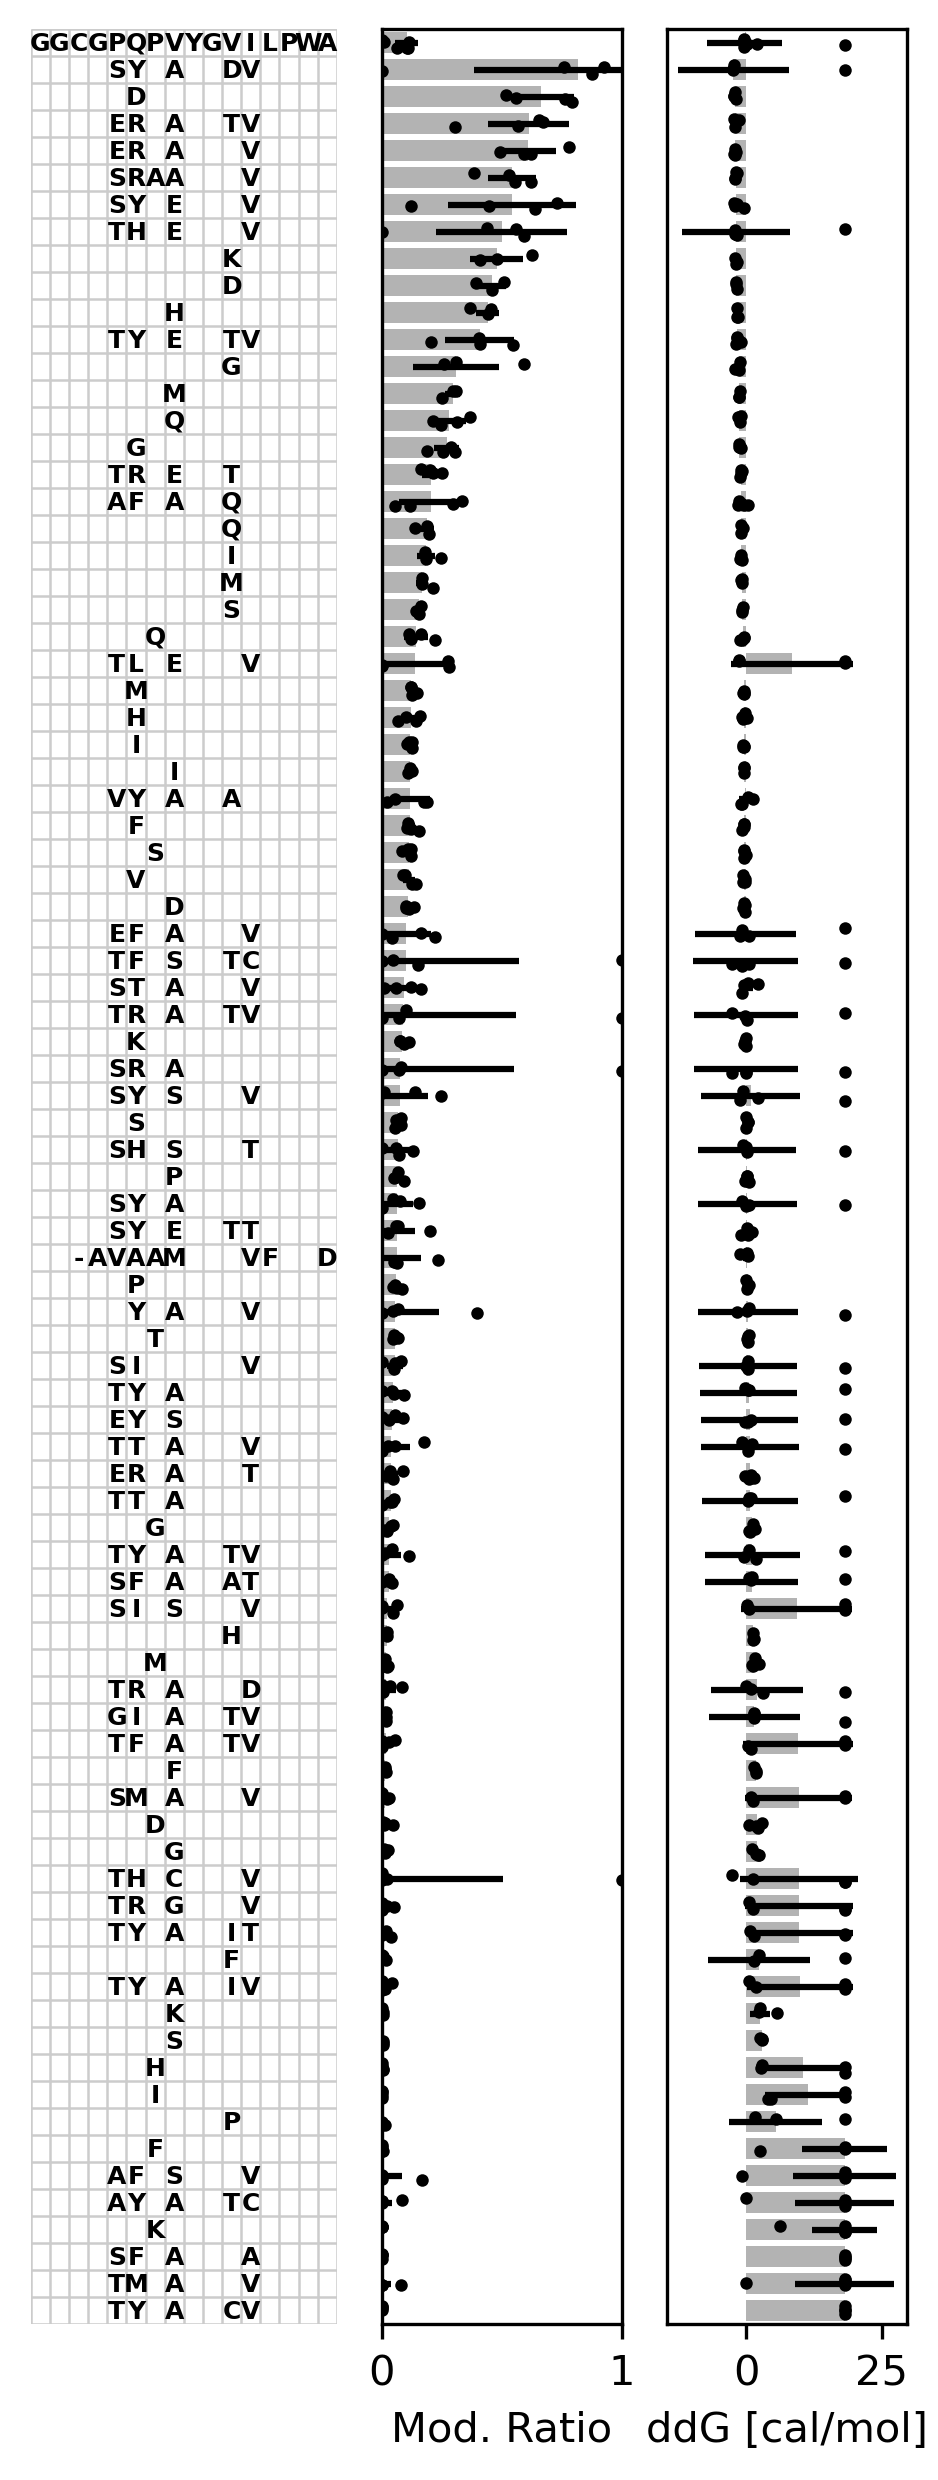

\n--- Generating Summary Plot (Clustal Color Scheme) ---


C:\Users\jordant\PycharmProjects\LCMS_RiPP\plotting_analysis_functions.py:238: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


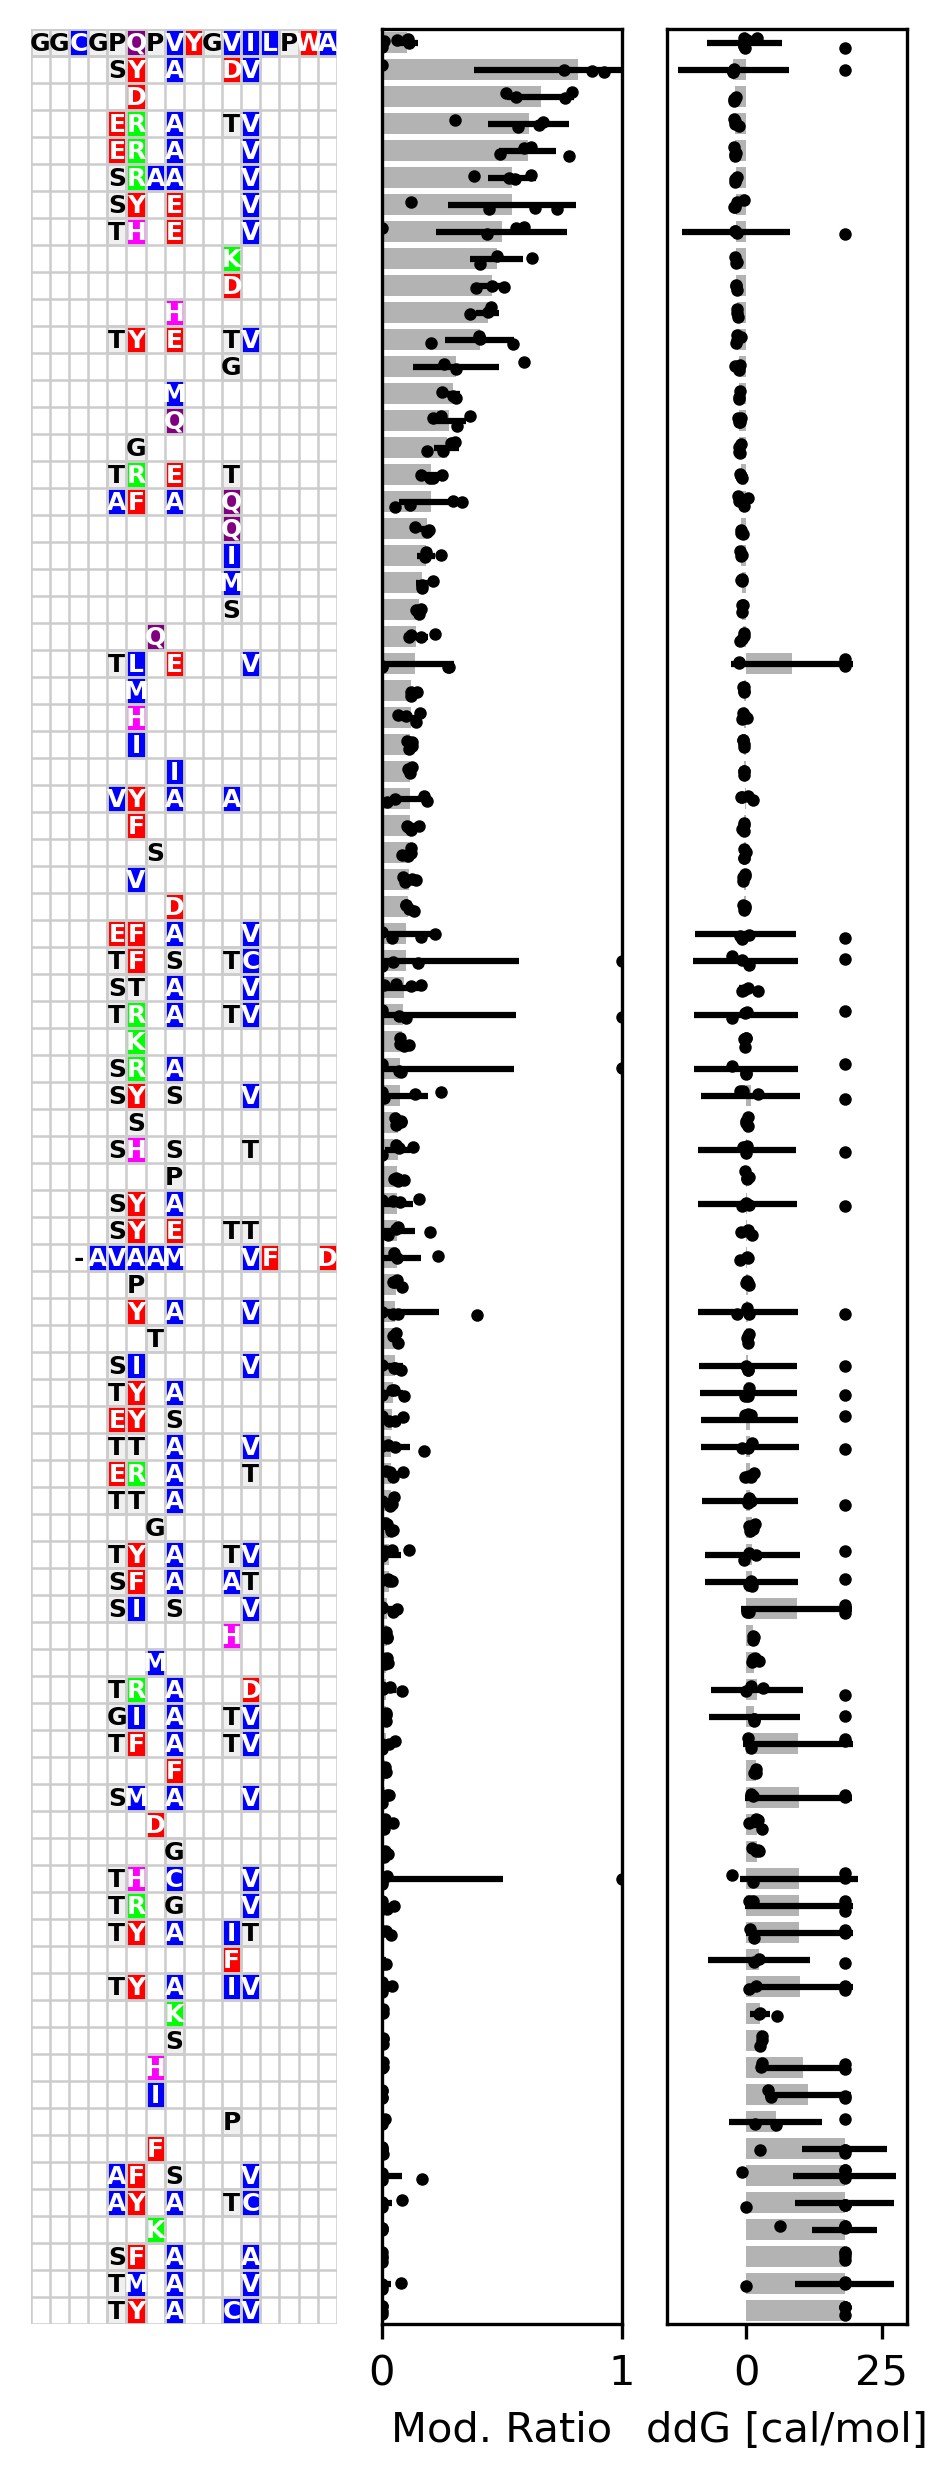

\n--- Generating Summary Plot (Hydrophobicity Color Scheme) ---


C:\Users\jordant\PycharmProjects\LCMS_RiPP\plotting_analysis_functions.py:238: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


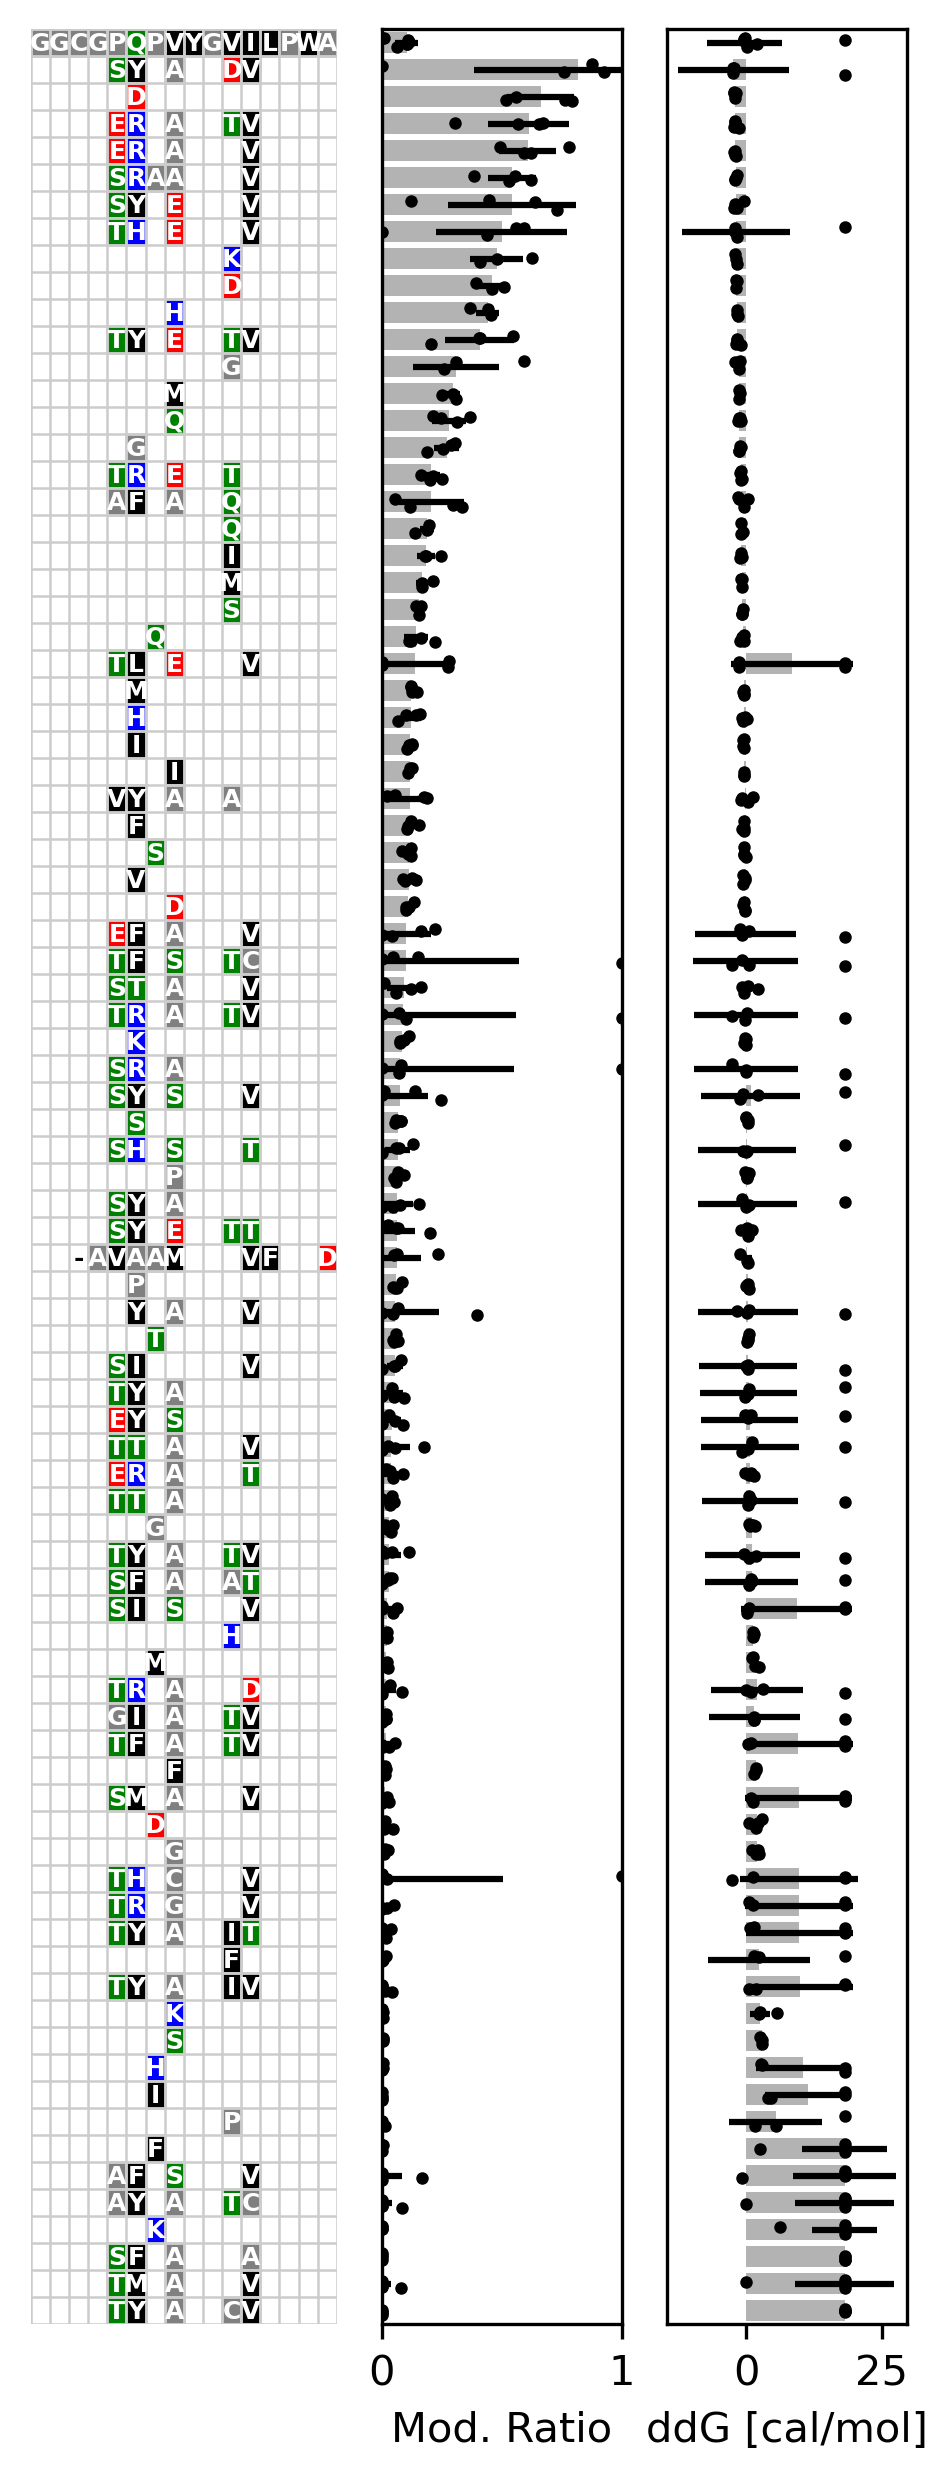

In [3]:
# 3. Example of using the new summary plot with color schemes
    # --- USER-DEFINED PARAMETERS FOR PLOTTING ---
ref_sequence_for_plot = "GGCGPQPVYGVILPWA"

# Filter for data relevant to this reference sequence
plot_data = mod_ratio_df[mod_ratio_df['peptide_sequence'].str.len() == len(ref_sequence_for_plot)]

plp_plot = plot_data[plot_data["enzyme"] == ("PlpX-PlpY")]

if not plot_data.empty:

    # --- END OF USER-DEFINED PARAMETERS ---

    if not plot_data.empty and ref_sequence_for_plot in plot_data['peptide_sequence'].values:
        print(f"\\n--- Generating Summary Plot (Default) ---")
        create_summary_alignment_plot(plp_plot, ref_sequence=ref_sequence_for_plot)

        print(f"\\n--- Generating Summary Plot (Clustal Color Scheme) ---")
        create_summary_alignment_plot(plp_plot, ref_sequence=ref_sequence_for_plot, color_scheme_name='clustal')

        print(f"\\n--- Generating Summary Plot (Hydrophobicity Color Scheme) ---")
        create_summary_alignment_plot(plp_plot, ref_sequence=ref_sequence_for_plot, color_scheme_name='hydrophobicity')
    else:
        print(f"\\nSkipping plot: Could not find data for reference sequence '{ref_sequence_for_plot}'.")
